# Decision Tree | TON_IoT | target: `type` (10-class, macro-averaged)
Tayyab (SP24-BCS-004). Settings and decisions are tracked in `AUDIT_LOG.md`; hyperparameter sources are in `HYPERPARAMETER_SOURCES.md` (both in the project root).

**Plan:** 20% test set (stratified), then stratified 5-fold on the other 80% (64% train / 16% validation per fold). Hyperparameters come from the papers, and the folds measure validation performance and stability, not tuning. The test set was used more than once: `max_depth=5` was replaced by `None` after the first test results, so the test scores may be slightly optimistic.

## 1. Imports and setup
**Q1.** Import the libraries and set a global `RANDOM_STATE` (same value for every model).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, log_loss, matthews_corrcoef,
                             confusion_matrix, classification_report)

RANDOM_STATE = 42
DATA_PATH = "../../../train_test_network.csv"

**Q2.** Define the Decision Tree hyperparameters (fixed, from the papers) and the duplicate-removal switch.

*Why a switch?* Whether to remove duplicates is still undecided in the team. See Q8.

In [2]:
# Dataset-specific hyperparameters (see HYPERPARAMETER_SOURCES.md)
# Source: Dharini, Janani & Katiravan (2026), "Efficient detection of intrusions in TON-IoT dataset using hybrid
# feature selection approach", Scientific Reports 16:7763, doi:10.1038/s41598-026-37834-y
# ("gini criterion, no fixed maximum depth, minimum split of two samples, and one sample per leaf"; random_state = 42)
HP = dict(criterion="gini", splitter="best", max_depth=None, min_samples_split=2, min_samples_leaf=1, random_state=RANDOM_STATE)

# Previous values (Li et al. 2024 / Sharma et al. 2025): max_depth=5, min_samples_split=5 -> underfitted `type`

DEDUPLICATE = False

## 2. Load the dataset
**Q3.** Load `train_test_network.csv`. How many rows and columns are there? (Expected: 211,043 x 44.)

In [3]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
print("Rows, columns:", df.shape)

Rows, columns: (211043, 44)


## 3. Explore the data
**Q4.** Show `head()`, `info()`, `describe()` and the class distribution of `type`. Is it balanced? Which class is the rarest?

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


<class 'pandas.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_ip                  211043 non-null  str    
 1   src_port                211043 non-null  int64  
 2   dst_ip                  211043 non-null  str    
 3   dst_port                211043 non-null  int64  
 4   proto                   211043 non-null  str    
 5   service                 211043 non-null  str    
 6   duration                211043 non-null  float64
 7   src_bytes               211043 non-null  int64  
 8   dst_bytes               211043 non-null  int64  
 9   conn_state              211043 non-null  str    
 10  missed_bytes            211043 non-null  int64  
 11  src_pkts                211043 non-null  int64  
 12  src_ip_bytes            211043 non-null  int64  
 13  dst_pkts                211043 non-null  int64  
 14  dst_ip_bytes            211043 

,src_port,dst_port,duration,src_bytes,dst_bytes,missed_bytes,src_pkts,src_ip_bytes,dst_pkts,dst_ip_bytes,dns_qclass,dns_qtype,dns_rcode,http_request_body_len,http_response_body_len,http_status_code,label
count,211043.000000,211043.000000,211043.000000,2.110430e+05,2.110430e+05,2.110430e+05,211043.000000,2.110430e+05,211043.000000,2.110430e+05,211043.000000,211043.000000,211043.000000,211043.000000,2.110430e+05,211043.000000,211043.000000
mean,38646.519543,3495.153770,7.700887,2.581136e+05,2.588046e+05,3.443234e+04,9.595220,7.760822e+02,3.846861,1.584687e+03,227.630805,3.610909,0.123989,0.065418,1.449295e+02,0.303905,0.763081
std,19307.271048,10191.624778,564.141946,1.709490e+07,1.802563e+07,5.261621e+06,91.778821,2.229703e+04,330.705796,1.901795e+05,2720.713562,23.797747,0.598804,9.243405,3.047244e+04,8.270377,0.425193
min,1.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,34608.000000,65.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,4.800000e+01,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
50%,44754.000000,80.000000,0.000170,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,8.200000e+01,1.000000,4.000000e+01,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
75%,51133.000000,1253.000000,0.054196,1.300000e+02,8.900000e+01,0.000000e+00,4.000000,4.150000e+02,2.000000,1.340000e+02,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
max,65528.000000,65467.000000,93516.929170,3.890855e+09,3.913853e+09,1.854527e+09,24623.000000,6.522626e+06,121942.000000,8.639552e+07,32769.000000,255.000000,5.000000,2338.000000,1.342438e+07,404.000000,1.000000


type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
ransomware    20000
scanning      20000
xss           20000
mitm           1043
Name: count, dtype: int64
type
normal        0.2369
backdoor      0.0948
ddos          0.0948
dos           0.0948
injection     0.0948
password      0.0948
ransomware    0.0948
scanning      0.0948
xss           0.0948
mitm          0.0049
Name: proportion, dtype: float64


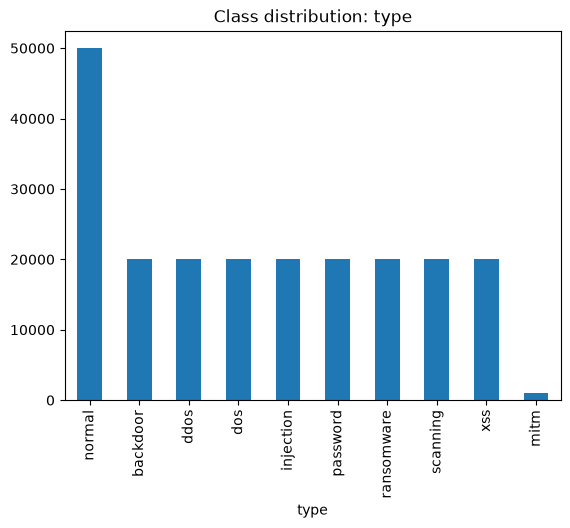

In [4]:
display(df.head())
df.info()
display(df.describe())
print(df["type"].value_counts())
print(df["type"].value_counts(normalize=True).round(4))
df["type"].value_counts().plot(kind="bar", title="Class distribution: type")
plt.show()

**Q5.** Replace the `-` placeholders with NaN and list the percentage of missing values per column.

In [5]:
df = df.replace("-", np.nan)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
display(missing_pct[missing_pct > 0].round(2))

ssl_issuer              99.99
ssl_subject             99.99
http_orig_mime_types    99.99
weird_addl              99.93
http_resp_mime_types    99.90
http_user_agent         99.86
http_uri                99.86
http_method             99.86
http_version            99.86
http_trans_depth        99.86
weird_notice            99.83
weird_name              99.83
ssl_established         99.81
ssl_resumed             99.81
ssl_version             99.81
ssl_cipher              99.81
dns_query               83.49
dns_rejected            83.41
dns_AA                  83.41
dns_RD                  83.41
dns_RA                  83.41
service                 62.56
dtype: float64

## 4. Clean the data
**Q6.** Drop columns that are more than 95% empty. How many were dropped? (Expected: 16, the `http_*`, `ssl_*`, `weird_*` columns.)

In [6]:
sparse_cols = missing_pct[missing_pct > 95].index.tolist()
print("Dropping", len(sparse_cols), "columns more than 95% empty:", sparse_cols)
df = df.drop(columns=sparse_cols)
print("Shape now:", df.shape)

Dropping 16 columns more than 95% empty: ['ssl_issuer', 'ssl_subject', 'http_orig_mime_types', 'weird_addl', 'http_resp_mime_types', 'http_user_agent', 'http_uri', 'http_method', 'http_version', 'http_trans_depth', 'weird_notice', 'weird_name', 'ssl_established', 'ssl_resumed', 'ssl_version', 'ssl_cipher']
Shape now: (211043, 28)


**Q7.** Drop the identifier columns (`src_ip`, `dst_ip`, `src_port`, `dst_port`). Why do they cause overfitting?

In [7]:
id_cols = ["src_ip", "dst_ip", "src_port", "dst_port"]
df = df.drop(columns=id_cols)
print("Shape now:", df.shape)

Shape now: (211043, 24)


**Q8.** How many duplicate rows are there now? Duplicates can land in both train and test, which inflates the scores; but removing them changes the dataset a lot (expected: ~117k duplicates, and `ransomware` falls from 20,000 to ~260 rows). Run once with `DEDUPLICATE = False` and once with `True`, and write both results in `AUDIT_LOG.md`.

In [8]:
n_dups = df.duplicated().sum()
print("Duplicate rows:", n_dups, f"({n_dups / len(df):.1%})")
print("Rows before:", len(df))
if DEDUPLICATE:
    df = df.drop_duplicates().reset_index(drop=True)
print("Rows after: ", len(df))
print(df["type"].value_counts())

Duplicate rows: 117159 (55.5%)
Rows before: 211043
Rows after:  211043
type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
ransomware    20000
scanning      20000
xss           20000
mitm           1043
Name: count, dtype: int64


## 5. Targets and split
**Q9.** Build the features `X` and the target `y` (`type`), without the other target column (leakage). Split 80/20 with stratification. Do the class shares match between train and test?

In [9]:
X = df.drop(columns=["label", "type"])   # both targets removed from the features (no leakage)
le = LabelEncoder()
y = pd.Series(le.fit_transform(df["type"]), index=df.index)
class_names = list(le.classes_)
print(dict(enumerate(class_names)))

# Stratify on `type` in BOTH notebooks, so the label and type models use the exact same rows
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=df["type"], random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class share:\n", y_train.value_counts(normalize=True).round(4))
print("Test class share:\n", y_test.value_counts(normalize=True).round(4))

{0: 'backdoor', 1: 'ddos', 2: 'dos', 3: 'injection', 4: 'mitm', 5: 'normal', 6: 'password', 7: 'ransomware', 8: 'scanning', 9: 'xss'}


Train: (168834, 22)  Test: (42209, 22)
Train class share:
 5    0.2369
6    0.0948
0    0.0948
9    0.0948
7    0.0948
1    0.0948
8    0.0948
2    0.0948
3    0.0948
4    0.0049
Name: proportion, dtype: float64
Test class share:
 5    0.2369
0    0.0948
6    0.0948
8    0.0948
7    0.0948
3    0.0948
9    0.0948
2    0.0948
1    0.0948
4    0.0050
Name: proportion, dtype: float64


## 6. Encode the features
**Q10.** Encode the categorical columns using the training set only: missing values as their own category, one-hot for low-cardinality columns, frequency encoding for `dns_query`. Why are encoders fitted after the split? Why is no scaling needed for trees?

In [10]:
# Encoders learn ONLY from the training set, then are applied to the test set.
onehot_cols = ["proto", "service", "conn_state", "dns_AA", "dns_RD", "dns_RA", "dns_rejected"]
freq_col = "dns_query"   # 700+ different values: one-hot would add too many columns

X_train = X_train.copy()
X_test = X_test.copy()

# Missing values in categorical columns become their own category
for c in onehot_cols + [freq_col]:
    X_train[c] = X_train[c].fillna("missing")
    X_test[c] = X_test[c].fillna("missing")

# Frequency encoding for dns_query (frequencies from the training set only)
freq_map = X_train[freq_col].value_counts(normalize=True)
X_train[freq_col] = X_train[freq_col].map(freq_map)
X_test[freq_col] = X_test[freq_col].map(freq_map).fillna(0)   # unseen in training -> 0

# One-hot encoding; the test set is aligned to the training columns
X_train = pd.get_dummies(X_train, columns=onehot_cols).astype(float)
X_test = pd.get_dummies(X_test, columns=onehot_cols).reindex(columns=X_train.columns, fill_value=0).astype(float)

print("Features after encoding:", X_train.shape[1])
print("Any NaN left?", X_train.isna().any().any(), X_test.isna().any().any())
# No scaling: decision trees split on thresholds, so feature scale does not matter.

Features after encoding: 52
Any NaN left? False False


## 7. Validation with stratified 5-fold
**Q11.** With the fixed hyperparameters, train on each fold's training part and score on its validation part. Is the validation score stable across folds (small standard deviation)? Does each fold keep every class?

In [11]:
# Stratified 5-fold on the 80% training set: each fold = 64% train / 16% validation of the full data
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold_rows = []
for i, (tr, va) in enumerate(skf.split(X_train, y_train), start=1):
    m = DecisionTreeClassifier(**HP)
    m.fit(X_train.iloc[tr], y_train.iloc[tr])
    pred = m.predict(X_train.iloc[va])
    fold_rows.append({"fold": i, "n_train": len(tr), "n_val": len(va),
                       "val_accuracy": accuracy_score(y_train.iloc[va], pred),
                       "val_macro_F1": f1_score(y_train.iloc[va], pred, average="macro")})
fold_df = pd.DataFrame(fold_rows)
display(fold_df.round(4))
print("Mean validation accuracy: %.4f +/- %.4f" % (fold_df.val_accuracy.mean(), fold_df.val_accuracy.std()))
print("Mean validation macro_F1: %.4f +/- %.4f" % (fold_df["val_macro_F1"].mean(), fold_df["val_macro_F1"].std()))

,fold,n_train,n_val,val_accuracy,val_macro_F1
0,1,135067,33767,0.9741,0.9451
1,2,135067,33767,0.9755,0.9460
2,3,135067,33767,0.9749,0.9474
3,4,135067,33767,0.9764,0.9504
4,5,135068,33766,0.9745,0.9464


Mean validation accuracy: 0.9751 +/- 0.0009
Mean validation macro_F1: 0.9471 +/- 0.0020


## 8. Final model
**Q12.** Train the final model on the full 80% training set with the same hyperparameters. How long does it take? How deep is the tree, and how many leaves?

In [12]:
model = DecisionTreeClassifier(**HP)
t0 = time.perf_counter()
model.fit(X_train, y_train)
train_time = time.perf_counter() - t0
print("Training time: %.3f s" % train_time)
print("Depth:", model.get_depth(), " Leaves:", model.get_n_leaves())

Training time: 0.578 s
Depth: 56  Leaves: 2464


## 9. Evaluation on the test set (used more than once: `max_depth` was revised after the first test results)
**Q13.** Predict on the test set and measure the inference latency (ms per sample, `predict()` only).

In [13]:
# Inference latency = time of predict() on the whole test set / number of test rows (ms per sample)
t0 = time.perf_counter()
y_pred = model.predict(X_test)
latency_ms = (time.perf_counter() - t0) / len(X_test) * 1000
y_proba = model.predict_proba(X_test)
print("Latency: %.6f ms/sample" % latency_ms)

Latency: 0.000321 ms/sample


**Q14.** Compute every metric required by `Results.xlsx`: Accuracy, Precision, Recall, F1, ROC-AUC, Log-Loss, FPR, MCC, and TP/TN/FP/FN. For `type`, use macro-averaging, one-vs-rest ROC-AUC, and macro-averaged one-vs-rest TP/TN/FP/FN. Which classes are hardest?

In [14]:
labels = np.arange(len(class_names))
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall    = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1        = f1_score(y_test, y_pred, average="macro", zero_division=0)
roc_auc   = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro", labels=labels)
logloss   = log_loss(y_test, y_proba, labels=labels)
mcc       = matthews_corrcoef(y_test, y_pred)

# One-vs-rest TP/TN/FP/FN per class, then macro-average
cm = confusion_matrix(y_test, y_pred, labels=labels)
TP = np.diag(cm)
FP = cm.sum(axis=0) - TP
FN = cm.sum(axis=1) - TP
TN = cm.sum() - (TP + FP + FN)
fpr = np.mean(FP / (FP + TN))

print(f"Accuracy {accuracy:.4f} | Precision {precision:.4f} | Recall {recall:.4f} | F1 {f1:.4f}  (macro)")
print(f"ROC-AUC {roc_auc:.4f} | Log-Loss {logloss:.4f} | FPR {fpr:.4f} | MCC {mcc:.4f}")
print(f"Macro TP {TP.mean():.2f} | TN {TN.mean():.2f} | FP {FP.mean():.2f} | FN {FN.mean():.2f}")
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

Accuracy 0.9766 | Precision 0.9479 | Recall 0.9516 | F1 0.9495  (macro)
ROC-AUC 0.9800 | Log-Loss 0.5103 | FPR 0.0026 | MCC 0.9732
Macro TP 4122.20 | TN 37889.40 | FP 98.70 | FN 98.70
              precision    recall  f1-score   support

    backdoor       1.00      1.00      1.00      4000
        ddos       0.98      0.97      0.98      4000
         dos       0.98      0.98      0.98      4000
   injection       0.97      0.96      0.96      4000
        mitm       0.70      0.74      0.72       209
      normal       1.00      0.99      1.00     10000
    password       0.99      0.98      0.98      4000
  ransomware       0.92      0.98      0.95      4000
    scanning       0.99      0.99      0.99      4000
         xss       0.95      0.91      0.93      4000

    accuracy                           0.98     42209
   macro avg       0.95      0.95      0.95     42209
weighted avg       0.98      0.98      0.98     42209



**Q15.** Compare train and test accuracy. Is the tree overfitting or underfitting? What do the validation-fold scores say? (`max_depth=None` puts no limit on the tree: watch for overfitting.)

In [15]:
train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, y_pred)
print(f"Train accuracy {train_acc:.4f} | Test accuracy {test_acc:.4f} | Gap {train_acc - test_acc:+.4f}")

Train accuracy 0.9886 | Test accuracy 0.9766 | Gap +0.0120


## 10. Visualizations
**Q16.** Plot the confusion matrix (row-normalised, so rare classes are readable).

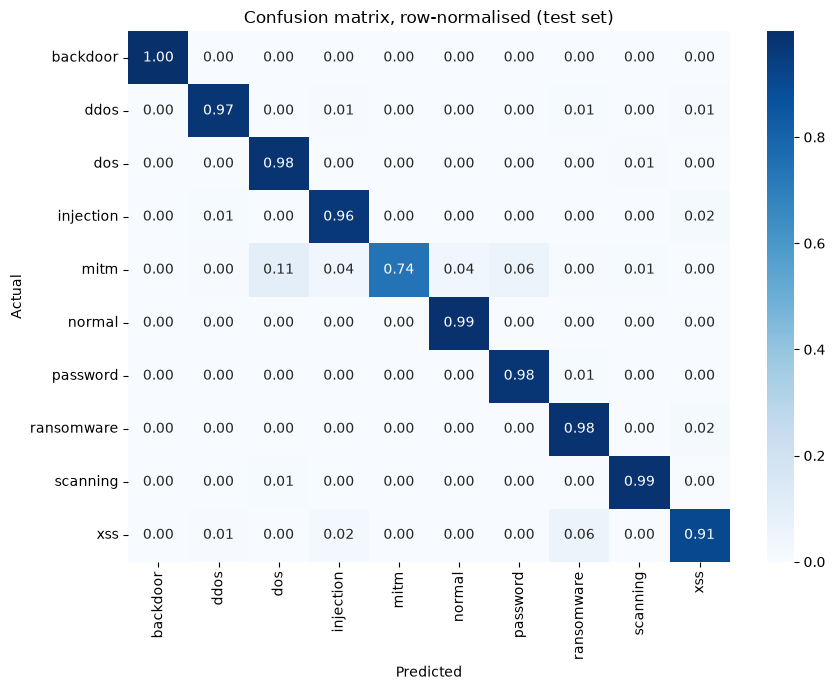

In [16]:
cm_norm = confusion_matrix(y_test, y_pred, labels=labels, normalize="true")
plt.figure(figsize=(9, 7))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion matrix, row-normalised (test set)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

**Q17.** Which features matter most to the tree?

src_ip_bytes      0.3053
src_bytes         0.0987
proto_tcp         0.0913
conn_state_REJ    0.0782
conn_state_SF     0.0772
src_pkts          0.0743
conn_state_OTH    0.0528
duration          0.0485
conn_state_S1     0.0426
dns_rejected_T    0.0405
dtype: float64

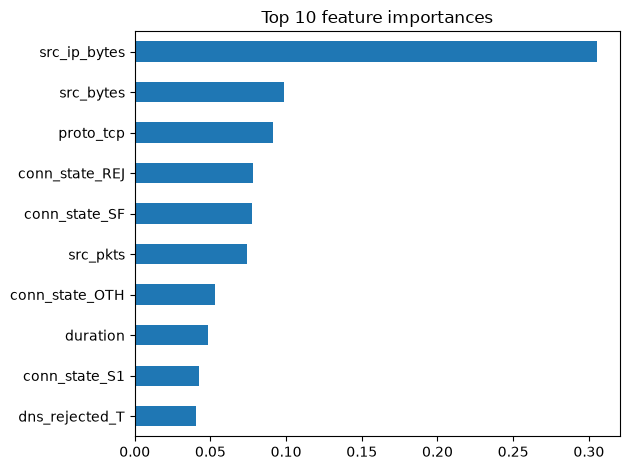

In [17]:
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(importances.head(10).round(4))
importances.head(10).sort_values().plot(kind="barh", title="Top 10 feature importances")
plt.tight_layout()
plt.show()

**Q18.** Plot the top levels of the tree. Do the first splits make sense for network attacks?

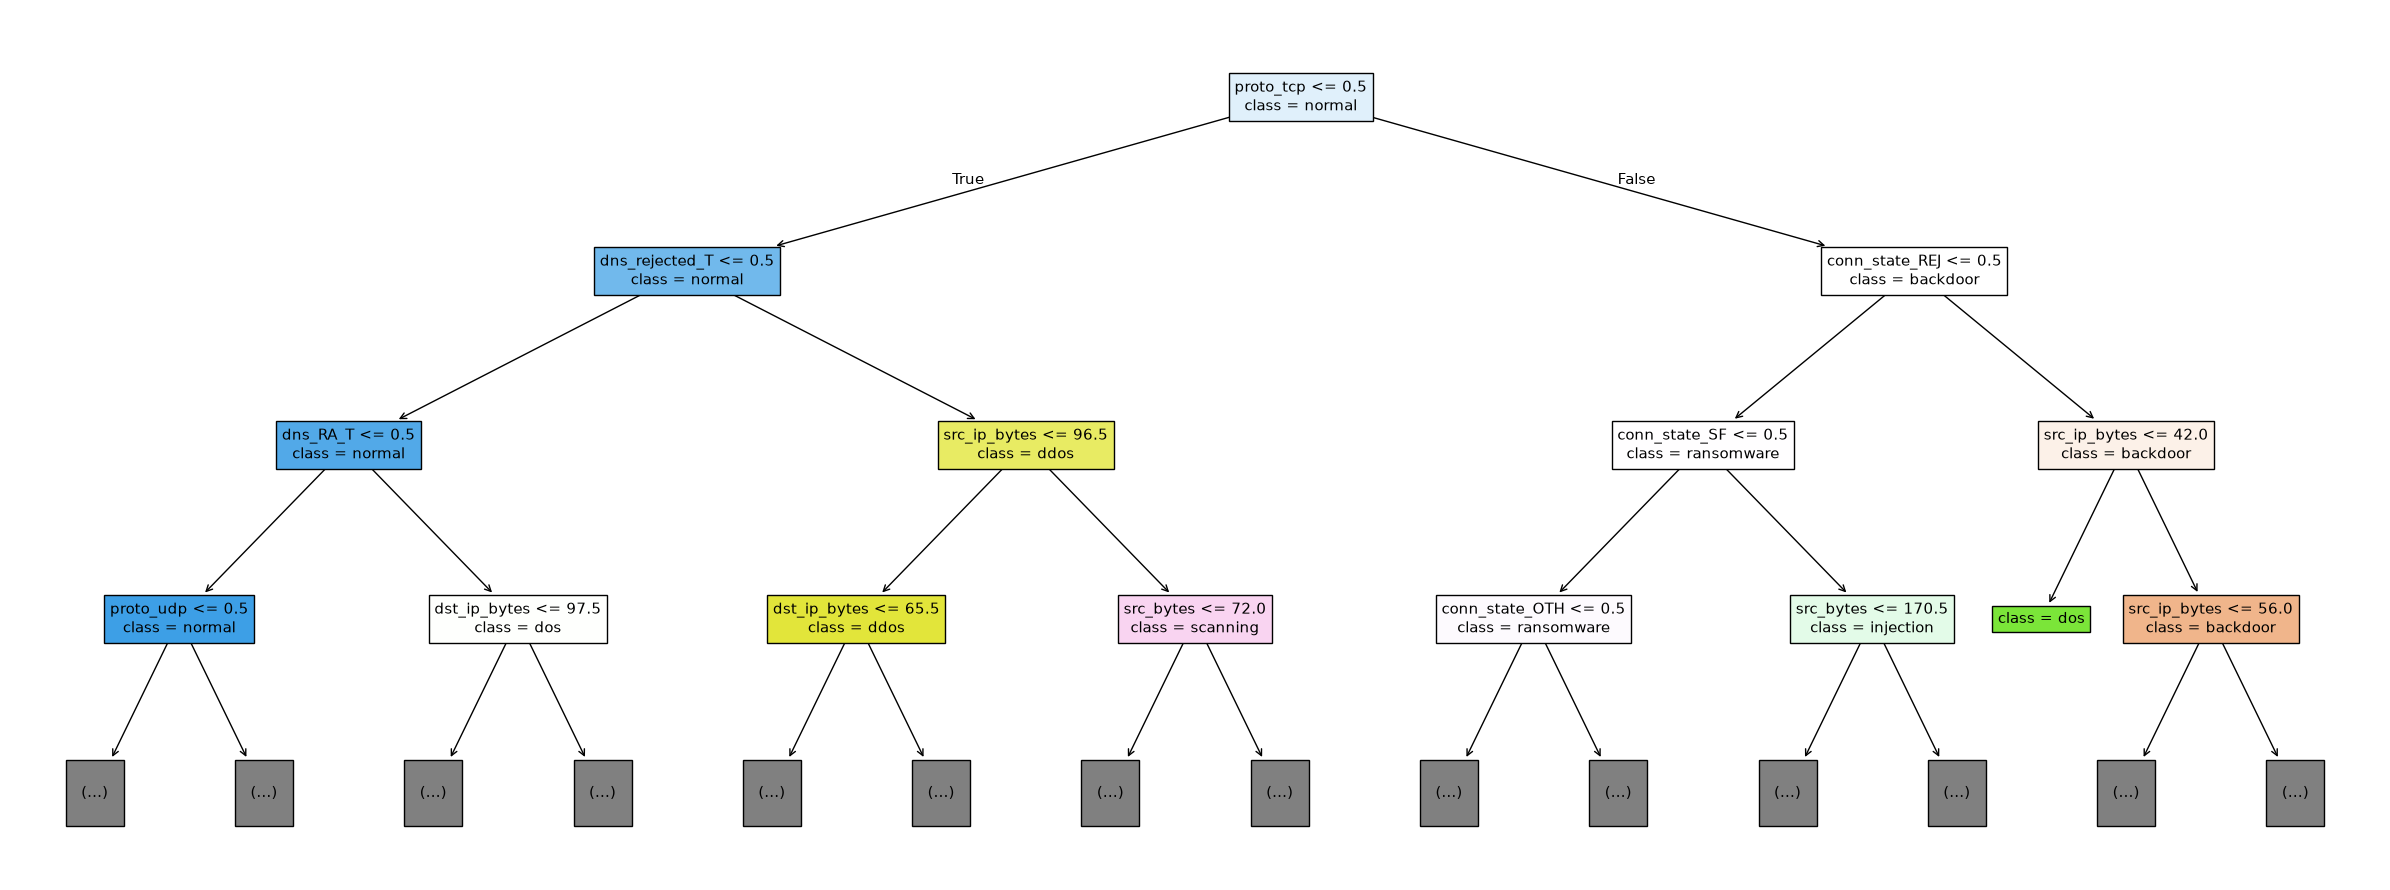

In [18]:
# Only the first 3 levels of the tree
fig, ax = plt.subplots(figsize=(24, 9))
nodes = plot_tree(model, feature_names=list(X_train.columns), class_names=class_names, filled=True,
                  max_depth=3, impurity=False, fontsize=11, ax=ax)

# Keep only the split question and the predicted class in each box;
# the "samples" and "value = [...]" lines make the boxes too wide and they overlap
for node in nodes:
    text = node.get_text()
    if "value" in text:
        keep = [line for line in text.splitlines() if "<=" in line or line.startswith("class")]
        node.set_text("\n".join(keep))

plt.tight_layout()
plt.show()

## 11. Results table
**Q19.** Collect all numbers in one table, in the same order as the *Decision Trees* row of `Results.xlsx`. Check that TP+TN+FP+FN equals the number of test rows (for `type`, it is per class). Copy the numbers into `AUDIT_LOG.md`. (Writing into `Results.xlsx` is decided later.)

In [19]:
results = pd.DataFrame([{
    "Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1-Score": f1,
    "ROC-AUC": roc_auc, "Log-Loss": logloss, "FPR": fpr, "MCC": mcc,
    "Inference Latency (ms/sample)": latency_ms, "Training time (s)": train_time,
    **{'TP': TP.mean(), 'TN': TN.mean(), 'FP': FP.mean(), 'FN': FN.mean()},
    "Test rows": len(y_test),
}], index=["Decision Tree - type (macro)"])
display(results.T)

,Decision Tree - type (macro)
Accuracy,0.976616
Precision,0.947894
Recall,0.951588
F1-Score,0.949535
ROC-AUC,0.979975
Log-Loss,0.510250
FPR,0.002585
MCC,0.973219
Inference Latency (ms/sample),0.000321
Training time (s),0.577558


## 12. Discussion (for the report)
**Q20.** Compare with the KNN, Random Forest and XGBoost rows (accuracy, F1, MCC, latency).

**Q21.** Which attack types are confused with each other, and why? How does the rare class (`mitm`, and `ransomware` if deduplicated) behave?

**Q22.** Limitations (unlimited depth chosen after the first test results, duplicates, dataset-specific features).

**Your notes:**